# Calculate Profile Likelihood
This notebook performs **Profile Likelihood (PL)** calculations for the full measurement horizon.
The initial parameter values are loaded from `Set_up_general.py` (via `initial_para`), which are defined in log10 space.


In [1]:
# add path
from pathlib import Path
import sys

# Dynamically resolve project root containing solver_config.py
project_root = Path.cwd().resolve()
while project_root != project_root.parent and not (project_root / "solver_config.py").exists():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# set up
from Set_up_general import * # for all relevant other files - general setup + figures


CasADi - 2026-10-19 14:41:37 WARNING("The options 't0', 'tf', 'grid' and 'output_t0' have been deprecated.
The same functionality is provided by providing additional input arguments to the 'integrator' function, in particular:
 * Call integrator(..., t0, tf, options) for a single output time, or
 * Call integrator(..., t0, grid, options) for multiple grid points.
The legacy 'output_t0' option can be emulated by including or excluding 't0' in 'grid'.
Backwards compatibility is provided in this release only.") [.../casadi/core/integrator.cpp:692]


Simulate plant, Generate artificial measurement data

In [2]:
# simulate plant
X_plant = p.full_int(F_int=F_int,x0=X0,U=U_feed,para=np.concatenate((para_plant.squeeze(),N0)),p=p)

# generate artificial measurements
Y_measurements = p.Measurement_Eq(X_plant,X_lb,k=np.arange(p.N_sample+1))

Calculate optimal parameter value

In [3]:
# set up profile likelihood problem class
PL = PL_class(Collocation=Collocation,Model = p,x_max = x_max,n_coll=n_coll,N_hor=p.N_sample+1,F_int =F_int,F =F_RHS,X_lb = X_lb,c_in=c_in,idx_not_opt=[],lb_para=lb_para, ub_para=ub_para) 

# initial parameter estimate - in log-space
para0 = np.log10(para_plant.squeeze())[:,None]

# get measurement data and reshape it into 1D array / row vector
Y_th = Y_measurements.T.reshape(-1,1).squeeze()

# get controls of time horizon and reshape it into 1D array / row vector
U_th_vec = U_feed.T.reshape(-1,1).squeeze()

# number of PL optimizations (multistart)
n_opt = 3

# set up matrices for PL multistart
Obj_opt_n = np.ones(n_opt)*1e9 # for objective function value
broken_n = np.zeros(n_opt) # for solver flag
para_opt_n = np.zeros((p.n_p,n_opt)) # for optimized parameters (log-space)

# initial parameter value for loop
para0_n  = para0

for idx_opt in range(n_opt): # multistart

        # solve PL problem
        para_opt, Obj_opt, broken = PL.PL_step(x_est_tk=X0, y_data=Y_th, u=U_th_vec, n_coll=n_coll, para0=para0_n, R=R_inv, N0=N0, para_fix=[])

        # save optimal values
        Obj_opt_n[idx_opt] = Obj_opt.full() # objective value
        broken_n[idx_opt] = broken # solver flag
        para_opt_n[:,idx_opt] = para_opt.squeeze() # optimal parameter value (log-space)

        # perturb multistart value
        para0_n = para0 + np.random.rand(p.n_p,1)*0.1

# find optimal values from multistart
idx_opt = np.where(np.min(Obj_opt_n)==Obj_opt_n)[0][0] # index of minimal objective
para_opt = para_opt_n[:,idx_opt][:,None] # get optimal parameter based on index
Obj_opt =  Obj_opt_n[idx_opt] # get optimal parameter based on index


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  |        0 (       0) 117.00us ( 10.64us)        11
       nlp_g  |   3.00ms (272.73us)   2.59ms (235.09us)        11
  nlp_grad_f  |        0 (       0) 195.00us ( 16.25us)        12
  nlp_hess_l  |  13.00ms (  1.30ms)  14.67ms (  1.47ms)        10
   nlp_jac_g  |   9.00ms (750.00us)   8.55ms (712.67us)        12
       total  |  79.00ms ( 79.00ms)  79.14ms ( 79.14ms)         1
      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  |        0 (       0) 147.00us ( 11.31us)        13
       nlp_g  |   6

C:\Users\jesbehre\AppData\Local\Temp\ipykernel_27448\2503201130.py:30: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Obj_opt_n[idx_opt] = Obj_opt.full() # objective value


      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  |        0 (       0) 129.00us (  7.17us)        18
       nlp_g  |   4.00ms (200.00us)   4.77ms (238.35us)        20
  nlp_grad_f  |        0 (       0) 287.00us ( 15.94us)        18
  nlp_hess_l  |  27.00ms (  1.69ms)  24.32ms (  1.52ms)        16
   nlp_jac_g  |  13.00ms (722.22us)  12.89ms (716.00us)        18
       total  | 123.00ms (123.00ms) 122.21ms (122.21ms)         1


Simulate with optimal parameter value

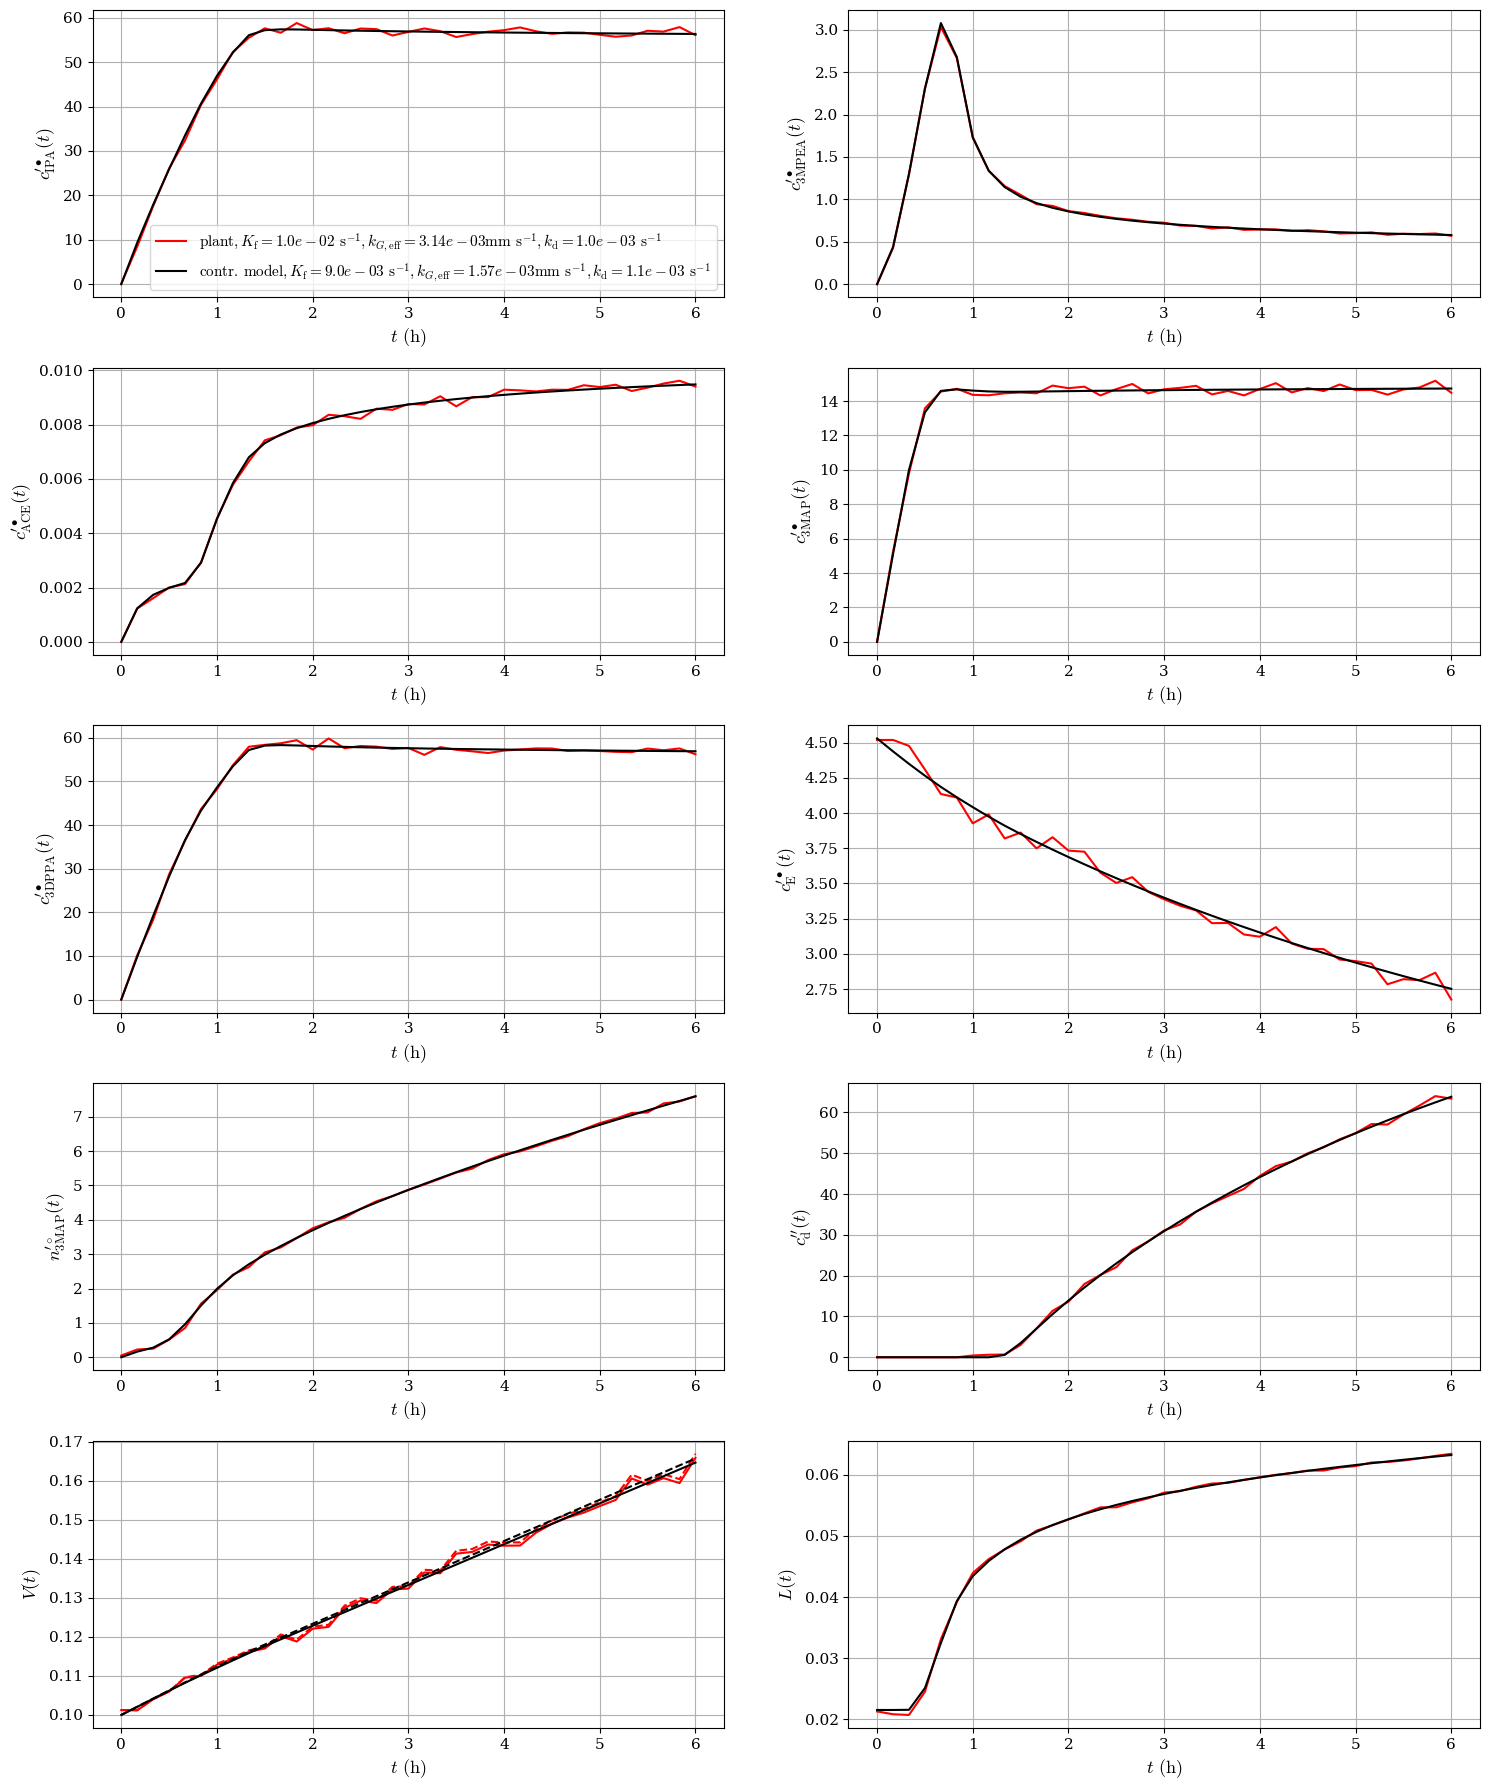

In [4]:
# simulate model with optimal parameter
X_opt = p.full_int(F_int=F_int,x0=X0,U=U_feed,para=np.concatenate((para_plant.squeeze(),N0)),p=p)
X_opt = p.Measurement_Eq(X_opt,np.maximum(0, X_lb),k=np.arange(p.N_sample+1),use_noise=0) # no noise used

plot_states_all(t, p, Y_measurements, X_opt, para_vals1=para_plant, para_vals2=initial_para[:,0])

Calculate profile likelihoods &!


In [5]:
# value of objective function
Obj_tk = np.ones((p.n_p,N_LL_full+1))*1e9

# store parameter
Para_PL = np.zeros((p.n_p,N_LL_full+1))

# track solver flag
PL_broken = np.zeros((p.n_p,N_LL_full+1))

In [6]:
# add optimal parameter to PL testing vector
var_para_full =  np.sort(np.concatenate((var_para_full,para_opt),axis = 1),axis = 1)

In [7]:
# number of PL optmization (multistart)
n_opt = 3

for idx_not_opt in range(p.n_p): # for all parameters that need to be optimized

        # create PL problem
        PL = PL_class(Collocation=Collocation,Model = p,x_max = x_max,n_coll=n_coll,N_hor=p.N_sample+1,F_int =F_int,F =F_RHS,X_lb = X_lb,c_in=c_in,idx_not_opt=[idx_not_opt],lb_para=lb_para, ub_para=ub_para) 
        
        # index of parameter
        idx_opt = np.arange(p.n_p) # set equal then delete index of unoptimized parameter
        idx_opt = np.delete(idx_opt, idx_not_opt) # index of free parameters (to be optimized)

        for j in range(N_LL_full+1): # over all testing parameter values for PL

                # fixed parameter value
                para_fix = var_para_full[idx_not_opt,j] # in log10 space

                # set up matrices for PL multistart
                Obj_opt_n = np.ones(n_opt)*1e9 # for objective function value
                broken_n = np.zeros(n_opt) # for solver flag
                para_opt_n = np.zeros((p.n_p-1,n_opt)) # for optimized parameters (log-space)

                # initial parameter value for loop
                para0_n  = para_opt[idx_opt]
                for n_multi in range(n_opt): # multistart
                        
                        # solve PL problem
                        para_opt_PL, Obj_opt_PL, broken = PL.PL_step(x_est_tk=X0, y_data=Y_th, u=U_th_vec, n_coll=n_coll, para0=para0_n, R=R_inv, N0=N0, para_fix=para_fix)

                        # save optimal values
                        Obj_opt_n[n_multi] = Obj_opt_PL.full() # objective value
                        broken_n[n_multi] = broken # solver flag
                        para_opt_n[:,n_multi] = para_opt_PL.squeeze() # optimal parameter value (log-space)

                        # perturb multistart value
                        para0_n = para_opt[idx_opt] + np.random.rand(p.n_p-1,1)

                # find optimal values from multistart
                idx_opt_multi = np.where(np.min(Obj_opt_n)==Obj_opt_n)[0][0] # index of minimal objective
                para_opt_PL = para_opt_n[:,idx_opt_multi] # get optimal parameter based on index
                Obj =  Obj_opt_n[idx_opt_multi] # get optimal parameter based on index

                # recreate parameter vector
                para_full = np.zeros(p.n_p)
                para_full[idx_opt] = 10**para_opt_PL.squeeze()
                para_full[idx_not_opt] = 10**para_fix
                
                # objective function value
                Obj_tk[idx_not_opt,j] = Obj
                
                # parameter vector
                Para_PL[idx_not_opt,j] = 10**para_fix

                # save solver flag
                PL_broken[idx_not_opt,j] = broken_n[idx_opt_multi]


      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  |        0 (       0)  81.00us (  6.75us)        12
       nlp_g  |   5.00ms (416.67us)   3.26ms (271.83us)        12
  nlp_grad_f  |        0 (       0) 214.00us ( 16.46us)        13
  nlp_hess_l  |  14.00ms (  1.27ms)  14.40ms (  1.31ms)        11
   nlp_jac_g  |  12.00ms (923.08us)   8.94ms (687.69us)        13
       total  |  85.00ms ( 85.00ms)  83.93ms ( 83.93ms)         1
      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  |        0 (       0) 102.00us (  5.37us)        19
       nlp_g  |   4.00ms (190.48us)   4.75ms (226.24us)        21
  nlp_grad_f  |        0 (       0) 269.00us ( 14.16us)        19
  nlp_hess_l  |  22.00ms (  1.29ms)  20.27ms (  1.19ms)        17
   nlp_jac_g  |   9.00ms (473.68us)  11.59ms (610.26us)        19
       total  |  97.00ms ( 97.00ms)  97.60ms ( 97.60ms)         1


C:\Users\jesbehre\AppData\Local\Temp\ipykernel_27448\658923183.py:31: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Obj_opt_n[n_multi] = Obj_opt_PL.full() # objective value


      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  |        0 (       0)  89.00us (  4.94us)        18
       nlp_g  |   6.00ms (300.00us)   3.87ms (193.75us)        20
  nlp_grad_f  |        0 (       0) 230.00us ( 12.78us)        18
  nlp_hess_l  |  19.00ms (  1.19ms)  18.30ms (  1.14ms)        16
   nlp_jac_g  |   8.00ms (444.44us)  10.43ms (579.67us)        18
       total  |  86.00ms ( 86.00ms)  86.35ms ( 86.35ms)         1
      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  |        0 (       0)  91.00us (  7.58us)        12
       nlp_g  |   4.00ms (333.33us)   2.84ms (236.92us)        12
  nlp_grad_f  |        0 (       0) 211.00us ( 16.23us)        13
  nlp_hess_l  |  14.00ms (  1.27ms)  14.23ms (  1.29ms)        11
   nlp_jac_g  |   9.00ms (692.31us)   8.89ms (684.15us)        13
       total  |  76.00ms ( 76.00ms)  75.21ms ( 75.21ms)         1
      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp

confidence interval

In [ ]:
################################################################ confidence interval ################################################################# 
# profile log-likelihood values
Log_Likelihood = Obj_tk / 2

# log-likelihood value at maximum likelihood estimate
Log_Likelihood_opt = Obj_opt / 2

# likelihood ratio function values
l_hat = Log_Likelihood - Log_Likelihood_opt

# alpha quantile threshold value (95% confidence, 1 degree of freedom)
Alpha_quantil =  chi2.ppf(0.95, 1) / 2

# parameter values of confidence interval
Para_Conf_Int = np.zeros((p.n_p, 2)) 
# objective function upper bounds of confidence interval
Obj_CI_ub = np.zeros((p.n_p, 2))
# objective function lower bounds of confidence interval
Obj_CI_lb = np.zeros((p.n_p, 2))
# parameters lower bounds of confidence interval
Bounds_CI_lb = np.zeros((p.n_p, 2)) 
# parameters upper bounds of confidence interval
Bounds_CI_ub = np.zeros((p.n_p, 2)) 

for m in range(p.n_p): # loop through parameters 

    # indices within confidence threshold
    idx_CI = np.where(l_hat[m, :] <= Alpha_quantil)[0]

    if idx_CI.size==0: # replace with outer limits if empty 
        idx_CI = np.array([0,len(l_hat[m, :])-1])
    # lower bound index of confidence interval
    lb_dalpha_C_int = np.min(idx_CI)
    # upper bound index of confidence interval
    ub_dalpha_C_int = np.max(idx_CI)

    # lower interpolation index
    idx_lb_dalpha_C_int = lb_dalpha_C_int - 1
    # upper interpolation index
    idx_ub_dalpha_C_int = ub_dalpha_C_int + 1

    # correct lower bound if index is out of range
    if idx_lb_dalpha_C_int < 0:
        idx_lb_dalpha_C_int = 0
    # correct upper bound if index is out of range
    if idx_ub_dalpha_C_int >= var_para_full.shape[1]:
        idx_ub_dalpha_C_int = var_para_full.shape[1] - 1

    # parameter values at lower bound interval
    Bounds_CI_lb[m, :] = var_para_full[m, idx_lb_dalpha_C_int],var_para_full[m, lb_dalpha_C_int]
    # parameter values at upper bound interval
    Bounds_CI_ub[m, :] = var_para_full[m, ub_dalpha_C_int], var_para_full[m, idx_ub_dalpha_C_int]

    # objective values at lower bound interval
    Obj_CI_lb[m, :] = Obj_tk[m, idx_lb_dalpha_C_int], Obj_tk[m, lb_dalpha_C_int]
    # objective values at upper bound interval
    Obj_CI_ub[m, :] = Obj_tk[m, ub_dalpha_C_int],Obj_tk[m, idx_ub_dalpha_C_int]

# cutoff objective value for confidence interval
Obj_CI = Log_Likelihood_opt * 2 + Alpha_quantil * 2

# slope of lower bound interpolation line
m_lb = np.diff(Obj_CI_lb, axis=1) / np.diff(Bounds_CI_lb, axis=1) # [1/(various units)] 
# intercept of lower bound interpolation line
n_lb = Obj_CI_lb[:, 0] - m_lb[:, 0] * Bounds_CI_lb[:, 0]

# interpolated lower bound of confidence interval
Conf_Int_lb = ((Obj_CI - n_lb) / m_lb[:, 0]).squeeze()

# slope of upper bound interpolation line
m_ub = np.diff(Obj_CI_ub, axis=1) / np.diff(Bounds_CI_ub, axis=1) # [1/(various units)] 
# intercept of upper bound interpolation line
n_ub = Obj_CI_ub[:, 0] - m_ub[:, 0] * Bounds_CI_ub[:, 0]

# interpolated upper bound of confidence interval
Conf_Int_ub = ((Obj_CI - n_ub) / m_ub[:, 0]).squeeze() 

# CI on bounds correction
for m in range(p.n_p): # loop through parameters 
    # handle boundary limits for lower bound
    if Bounds_CI_lb[m, 0] == Bounds_CI_lb[m, 1]:
        Conf_Int_lb[m] = Bounds_CI_lb[m, 0] 
    # handle boundary limits for upper bound
    if Bounds_CI_ub[m, 0] == Bounds_CI_ub[m, 1]:
        Conf_Int_ub[m] = Bounds_CI_ub[m, 0] 

# consolidated confidence intervals matrix
Conf_Int = np.column_stack((Conf_Int_lb, Conf_Int_ub))t

Save Results

In [9]:
results_PL = {
        'var_para_full': var_para_full,
        'Y_measurements': Y_measurements,
        'para_opt': para_opt,
        'PL_broken': PL_broken,
        'Obj_tk': Obj_tk,
        'Obj_opt':Obj_opt,
        'Conf_Int': Conf_Int,
    }

# Save comparison results for all parameter sets to dataset_PL.npz
np.savez("dataset_PL.npz", **results_PL)